# ENG2440 Assignment 3 — Starter notebook

Name: Yintong Wang • Student ID: 25011183

This is an unexecuted scaffold, not a completed solution. Replace TODOs with your own implementation, outputs and interpretation. Requirements summarized from the supplied handout; consult it for the full rubric.


## 0. Setup
Launch Jupyter from this folder so relative paths resolve. Install requirements first. The dataset cell downloads BBBP on first execution. No data or models have been downloaded by this scaffold.


In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch_geometric.datasets import MoleculeNet
from src.config import *

assert Path("src/config.py").exists(), "Launch Jupyter from the project root."
random.seed(SPLIT_SEED)
np.random.seed(SPLIT_SEED)
torch.manual_seed(SPLIT_SEED)
print("PyTorch:", torch.__version__)
# TODO: record package versions and hardware; document reproducibility limitations.


Matplotlib is building the font cache; this may take a moment.


/opt/anaconda3/envs/tradingagents/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/tradingagents/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.0


## A. Define the task and inspect the dataset (10 marks)


### A1. Input, output, unit of analysis and intended use [2]

State the input, output, molecule-level unit of analysis and intended technical use. Explain positive and negative labels.


In [2]:
# TODO: A1 — Input, output, unit of analysis and intended use.

task = {
    "Input": "A molecule represented by a SMILES string, converted into a molecular graph",
    "Output": "One probability of blood-brain barrier penetration per molecule",
    "Unit of analysis": "Molecule",
    "Intended use": "Educational prediction of BBBP research labels",
    "Positive label (1)": "Labelled as penetrating the blood-brain barrier",
    "Negative label (0)": "Labelled as non-penetrating",
}

for name, description in task.items():
    print(f"{name}: {description}")

print("Scope: predictions are not for direct clinical use, only for educational purposes.")

Input: A molecule represented by a SMILES string, converted into a molecular graph
Output: One probability of blood-brain barrier penetration per molecule
Unit of analysis: Molecule
Intended use: Educational prediction of BBBP research labels
Positive label (1): Labelled as penetrating the blood-brain barrier
Negative label (0): Labelled as non-penetrating
Scope: predictions are not for direct clinical use, only for educational purposes.


### A2. Dataset audit, canonical SMILES and cleaning [3]

Load the full dataset. Report size, missing/non-finite labels, invalid or empty graphs, class counts and proportions. Canonicalize every valid SMILES using RDKit; identify duplicate molecules, including different original SMILES, and check label consistency.

**Required cleaning before splitting:** remove invalid SMILES/empty graphs; keep one record per consistent canonical-SMILES group; remove all records in conflicting-label groups. Report counts and document handling of unusable labels.


In [3]:
from rdkit import Chem
dataset = MoleculeNet(root=str(DATA_ROOT), name="BBBP")
print(dataset)
print("Number of molecules:", len(dataset))

# TODO: audit, canonicalize and clean the full dataset.

rows = []

for i, graph in enumerate(dataset):
    mol = Chem.MolFromSmiles(graph.smiles)
    valid = mol is not None and mol.GetNumAtoms() > 0

    rows.append({
        "index": i,
        "smiles": graph.smiles,
        "canonical": Chem.MolToSmiles(mol) if valid else None,
        "label": graph.y.item(),
        "empty_graph": graph.num_nodes == 0,
    })

df = pd.DataFrame(rows)

print("Dataset size:", len(df))
print("Missing / non-finite labels:", (~np.isfinite(df["label"])).sum())
print("Invalid / empty SMILES:", df["canonical"].isna().sum())
print("Empty graphs:", df["empty_graph"].sum())

print("Class counts:")
print(df["label"].value_counts())
print("Class proportions:")
print(df["label"].value_counts(normalize=True))

# Find repeated molecules, conflicting labels
groups = df.groupby("canonical")
duplicates = groups.agg(
    records=("index", "size"),
    smiles_versions=("smiles", "nunique"),
    label_count=("label", "nunique"),
)
duplicates = duplicates[duplicates["records"] > 1]
conflicts = duplicates.index[duplicates["label_count"] > 1]

print("Duplicate groups:", len(duplicates))
print("Records in duplicate groups:", duplicates["records"].sum())
print("Extra duplicate records:", (duplicates["records"] - 1).sum())
print("Groups with different SMILES:", (duplicates["smiles_versions"] > 1).sum())
print("Conflicting-label groups:", len(conflicts))
print("Records in conflicting groups:", df["canonical"].isin(conflicts).sum())
display(duplicates)

# Remove invalid records and all conflicting groups.
bad_structure = df["canonical"].isna() | df["empty_graph"]
bad_label = ~np.isfinite(df["label"]) | ~df["label"].isin([0, 1])
remove = bad_structure | bad_label | df["canonical"].isin(conflicts)

clean_df = df[~remove].copy()
print("Invalid-structure records:", bad_structure.sum())
print("Unusable-label records:", bad_label.sum())
print("Records removed before deduplication:", remove.sum())

# Keep one copy of each remaining molecule
before = len(clean_df)
clean_df = clean_df.drop_duplicates("canonical").reset_index(drop=True)
clean_graphs = [dataset[int(i)] for i in clean_df["index"]]

print("Consistent duplicates removed:", before - len(clean_df))
print("Total records removed:", len(df) - len(clean_df))
print("Clean dataset size:", len(clean_df))
print("Clean class counts:")
print(clean_df["label"].value_counts())
print("Clean class proportions:")
print(clean_df["label"].value_counts(normalize=True))


BBBP(2039)
Number of molecules: 2039


[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not r

Dataset size: 2039
Missing / non-finite labels: 0
Invalid / empty SMILES: 0
Empty graphs: 0
Class counts:
label
1.0    1560
0.0     479
Name: count, dtype: int64
Class proportions:
label
1.0    0.765081
0.0    0.234919
Name: proportion, dtype: float64
Duplicate groups: 60
Records in duplicate groups: 124
Extra duplicate records: 64
Groups with different SMILES: 60
Conflicting-label groups: 10
Records in conflicting groups: 20


[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors
[01:32:38] WARNING: not removing hydrogen atom without neighbors


,records,smiles_versions,label_count
canonical,,,
C=COC=C,2,2,1
CC(=O)NCCCOc1cccc(CN2CCCCC2)c1,2,2,1
CC(=O)Nc1ccc(O)cc1,2,2,1
CC(=O)Nc1nnc(S(N)(=O)=O)s1,2,2,1
CC(=O)Oc1ccccc1C(=O)O,2,2,2
CC(C)(C)OC(=O)CCCc1ccc(N(CCCl)CCCl)cc1,2,2,1
CC(C)c1cccc(C(C)C)c1O,2,2,1
CC(C)c1nc(-c2ncn3c2CN(C)C(=O)c2c(Cl)cccc2-3)no1,2,2,1
CC(CN1c2ccccc2Sc2ccccc21)N(C)C,2,2,1


Invalid-structure records: 0
Unusable-label records: 0
Records removed before deduplication: 20
Consistent duplicates removed: 54
Total records removed: 74
Clean dataset size: 1965
Clean class counts:
label
1.0    1500
0.0     465
Name: count, dtype: int64
Clean class proportions:
label
1.0    0.763359
0.0    0.236641
Name: proportion, dtype: float64


**Observed results:** The loader returned 2,039 molecules with no non-finite labels or invalid/empty graphs in this loaded dataset. There were 60 duplicate groups (124 records), all with differing original SMILES. Ten groups had conflicting labels, so all 20 records were removed; another 54 consistent duplicate records were removed. The cleaned dataset contains 1,965 molecules: 1,500 positives (76.34%) and 465 negatives (23.66%).


### A3. At least six molecular structures from both classes [2]

Display at least six structures spanning both classes. Include each molecule’s SMILES and label.


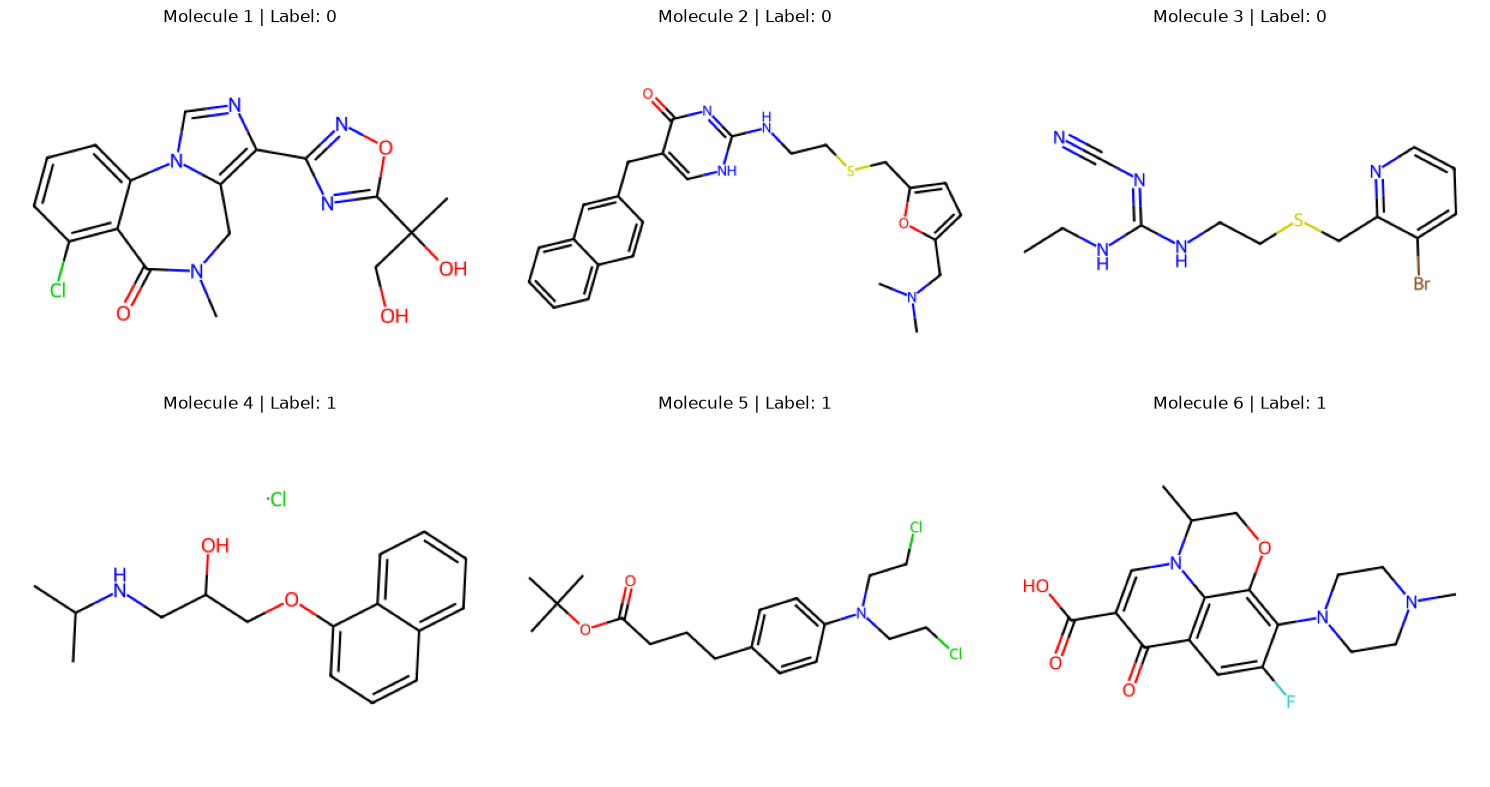

Molecule 1 | Label: 0
OCC(C)(O)c1onc(c2ncn3c2CN(C)C(c4c3cccc4Cl)=O)n1

Molecule 2 | Label: 0
c1cc2c(cc(CC3=CNC(=NC3=O)NCCSCc3oc(cc3)CN(C)C)cc2)cc1

Molecule 3 | Label: 0
CCNC(=NC#N)NCCSCc1c(cccn1)Br

Molecule 4 | Label: 1
[Cl].CC(C)NCC(O)COc1cccc2ccccc12

Molecule 5 | Label: 1
C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl

Molecule 6 | Label: 1
c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO3)=O



In [4]:
# TODO: A3 — At least six molecular structures from both classes.
from rdkit.Chem import Draw

# Pick three molecules from each class.
examples = pd.concat([
    clean_df[clean_df["label"] == 0].head(3),
    clean_df[clean_df["label"] == 1].head(3),
])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for number, (ax, (_, row)) in enumerate(zip(axes.flat, examples.iterrows()), start=1):
    mol = Chem.MolFromSmiles(row["smiles"])
    ax.imshow(Draw.MolToImage(mol, size=(400, 300)))
    ax.set_title(f"Molecule {number} | Label: {int(row['label'])}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Print the full SMILES below the figure.
for number, (_, row) in enumerate(examples.iterrows(), start=1):
    print(f"Molecule {number} | Label: {int(row['label'])}")
    print(row["smiles"])
    print()


### A4. Atom/bond distributions and one graph [3]

Summarize atom-count and bond-count distributions; distinguish directed edges from chemical bonds. Inspect one graph and report x.shape, edge_index.shape, edge_attr.shape, y and smiles.


x torch.Size([20, 9])
edge_index torch.Size([2, 40])
edge_attr torch.Size([40, 3])
y: tensor([[1.]])
smiles: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not removing hydrogen atom without neighbors
[01:32:39] WARNING: not r

,atoms,bonds
count,1965.00,1965.00
mean,24.22,26.13
std,10.67,11.79
min,2.00,1.00
25%,18.00,19.00
50%,23.00,25.00
75%,29.00,31.00
max,132.00,145.00


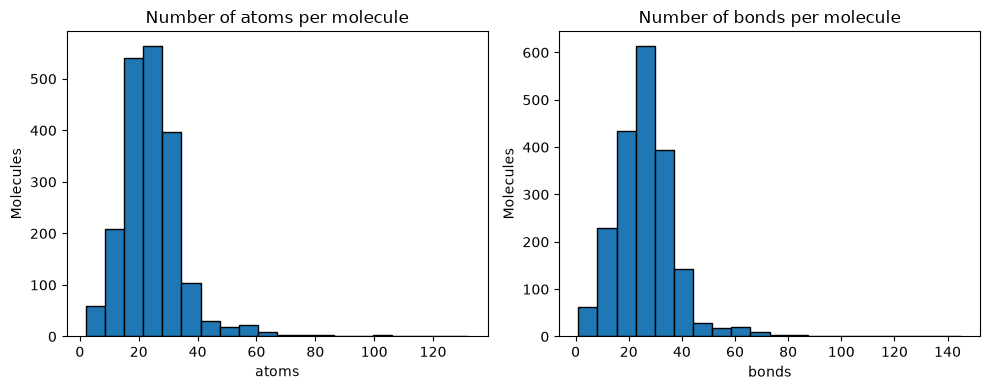

x.shape: torch.Size([20, 9])
edge_index.shape: torch.Size([2, 40])
edge_attr.shape: torch.Size([40, 3])
y: tensor([[1.]])
smiles: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [5]:
graph = dataset[0]
for attribute in ("x", "edge_index", "edge_attr"):
    print(attribute, getattr(graph, attribute).shape)
print("y:", graph.y)
print("smiles:", graph.smiles)

# TODO: summarize atom-count and bond-count distributions.

rows = []
for smiles in clean_df["smiles"]:
    mol = Chem.MolFromSmiles(smiles)
    rows.append({
        "atoms": mol.GetNumAtoms(),
        "bonds": mol.GetNumBonds(),
    })

counts = pd.DataFrame(rows)
display(counts.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["atoms", "bonds"]):
    ax.hist(counts[name], bins=20, edgecolor="black")
    ax.set_title(f"Number of {name} per molecule")
    ax.set_xlabel(name)
    ax.set_ylabel("Molecules")

plt.tight_layout()
plt.show()


graph = clean_graphs[0]

print("x.shape:", graph.x.shape)
print("edge_index.shape:", graph.edge_index.shape)
print("edge_attr.shape:", graph.edge_attr.shape)
print("y:", graph.y)
print("smiles:", graph.smiles)

**Observed results:** The cleaned molecules have a mean of 24.22 atoms and 26.13 bonds; medians are 23 atoms and 25 bonds. Counts range from 2–132 atoms and 1–145 bonds, indicating substantial size variation. The example has 20 atoms and 20 bonds: x is [20,9], edge_index [2,40] and edge_attr [40,3]. Its label is 1. The disconnected chlorine fragment is retained by the supplied representation.


## B. Construct and batch molecular graphs (12 marks)


### B1. Atom/bond representation and categorical encoding [3]

Explain nodes, edges and features. Identify every categorical feature column. Encode all atom and bond categories using one-hot encoding or trainable embeddings; state the method. Do not use category IDs as continuous values.


In [6]:
# TODO: B1 — Atom/bond representation and categorical encoding.

import torch.nn.functional as F
from torch_geometric.utils.smiles import x_map, e_map

print("Atom columns:", list(x_map))
print("Bond columns:", list(e_map))

# one-hot encode features
def one_hot_features(features, categories):
    columns = []
    for i, values in enumerate(categories.values()):
        column = F.one_hot(features[:, i], num_classes=len(values))
        columns.append(column)
    return torch.cat(columns, dim=1).float()


encoded_graphs = []

for graph in clean_graphs:
    encoded = graph.clone()
    encoded.x = one_hot_features(graph.x, x_map)
    encoded.edge_attr = one_hot_features(graph.edge_attr, e_map)
    encoded_graphs.append(encoded)

print("Atom features:", clean_graphs[0].x.shape, "to", encoded_graphs[0].x.shape)
print("Bond features:", clean_graphs[0].edge_attr.shape, "to", encoded_graphs[0].edge_attr.shape)


Atom columns: ['atomic_num', 'chirality', 'degree', 'formal_charge', 'num_hs', 'num_radical_electrons', 'hybridization', 'is_aromatic', 'is_in_ring']
Bond columns: ['bond_type', 'stereo', 'is_conjugated']
Atom features: torch.Size([20, 9]) to torch.Size([20, 177])
Bond features: torch.Size([40, 3]) to torch.Size([40, 30])


B1: The atom columns describe element, chirality, total degree, formal charge, hydrogen count, radical electrons, hybridization, aromaticity and ring membership. Bond columns describe bond type, stereochemistry and conjugation. One-hot blocks encode categories without numerical ordering.


### B2. Chemical structure and node–edge graph [3]

Display the same molecule in both views and explain atom/bond correspondence.


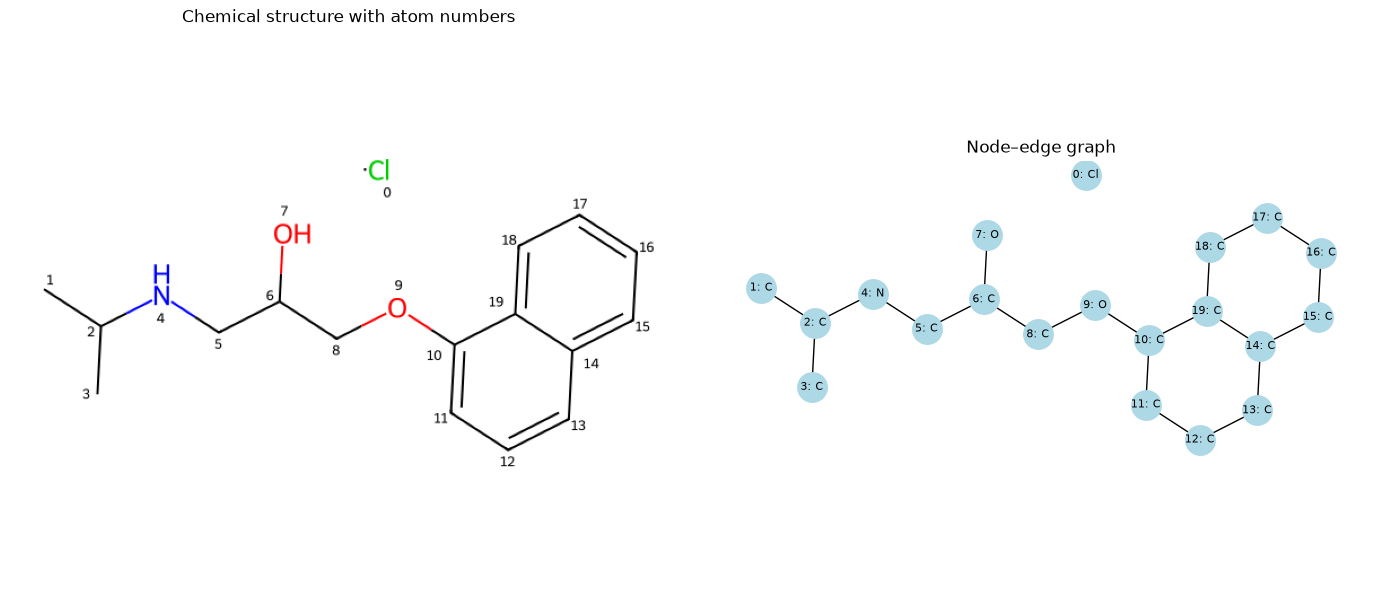

SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12
Label: 1


In [7]:
# TODO: B2 — Chemical structure and node–edge graph.

import networkx as nx
from rdkit.Chem import rdDepictor

# Use the first cleaned molecule in both views.
graph = clean_graphs[0]
mol = Chem.MolFromSmiles(graph.smiles)
rdDepictor.Compute2DCoords(mol)

labels = {}
positions = {}
for atom in mol.GetAtoms():
    i = atom.GetIdx()
    atom.SetProp("atomNote", str(i))
    labels[i] = f"{i}: {atom.GetSymbol()}"
    point = mol.GetConformer().GetAtomPosition(i)
    positions[i] = (point.x, point.y)

# An undirected graph shows each bond once.
network = nx.Graph()
network.add_nodes_from(range(graph.num_nodes))
network.add_edges_from(graph.edge_index.t().tolist())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(Draw.MolToImage(mol, size=(600, 500)))
axes[0].set_title("Chemical structure with atom numbers")
axes[0].axis("off")

nx.draw(network, pos=positions, labels=labels, ax=axes[1],
        node_color="lightblue", node_size=450, font_size=8)
axes[1].set_title("Node–edge graph")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()

print("SMILES:", graph.smiles)
print("Label:", int(graph.y.item()))


_Interpretation:_

Carbon atom 0 becomes node 0, and oxygen atom 1 becomes node 1.


Clarification: the carbon/oxygen sentence above is an illustrative correspondence, not a claim about the actual first two atoms. The labels on the plotted molecule give its actual atom identities.


### B3. DataLoader and batch shapes [3]

Create a PyG DataLoader. Print and explain x, edge_index, edge_attr, batch and y shapes for one batch.


In [8]:
# TODO: B3 — DataLoader and batch shapes.

from torch_geometric.loader import DataLoader


loader = DataLoader(encoded_graphs, batch_size=4, shuffle=False)
batch = next(iter(loader))

print("Number of graphs:", batch.num_graphs)
print("x:", batch.x.shape)
print("edge_index:", batch.edge_index.shape)
print("edge_attr:", batch.edge_attr.shape)
print("batch:", batch.batch.shape)
print("y:", batch.y.shape)

print("Atoms per graph:", torch.bincount(batch.batch))
print("Labels:", batch.y.view(-1))


Number of graphs: 4
x: torch.Size([90, 177])
edge_index: torch.Size([2, 188])
edge_attr: torch.Size([188, 30])
batch: torch.Size([90])
y: torch.Size([4, 1])
Atoms per graph: tensor([20, 23, 26, 21])
Labels: tensor([1., 1., 1., 1.])


_Interpretation:_

 x has one row per atom; edge_index has two rows for source/destination indices; edge_attr has one row per directed edge. batch assigns each atom to a molecule, while y contains one label per molecule. The combined graphs stay disconnected.


### B4. Graph, label and batching checks [3]

Check finite labels, at least one atom in every retained graph, one label per graph in a batch and no molecules lost during batching.


In [9]:
# TODO: B4 — Graph, label and batching checks.

# Check each graph and give it an ID.
for i, graph in enumerate(encoded_graphs):
    assert graph.num_nodes > 0, "Empty graph"
    assert torch.isfinite(graph.y).all(), "Non-finite label"
    graph.graph_id = torch.tensor([i])

# Check labels and track every molecule through batching.
check_loader = DataLoader(encoded_graphs, batch_size=4, shuffle=False)
seen = []

for batch in check_loader:
    assert batch.y.numel() == batch.num_graphs, "Wrong number of labels"
    seen.extend(batch.graph_id.tolist())

assert sorted(seen) == list(range(len(encoded_graphs))), "Missing or repeated molecule"


print("Molecules batched:", len(seen), "of", len(encoded_graphs))



Molecules batched: 1965 of 1965


_Interpretation:_

All graphs contain at least one atom. All labels are finite, and every batch has one label per graph. No molecules were lost or repeated.


## C. Create random and scaffold-based splits (13 marks)


### C1. Stratified random and Bemis–Murcko scaffold splits [4]

Using cleaned data and one fixed split seed, create separate 70:15:15 random and scaffold evaluations. Keep scaffold groups intact. Document invalid/acyclic molecule handling and deviations from target sizes. Save and reuse the splits across models and training seeds.


In [ ]:
# TODO: C1 — Stratified random and Bemis–Murcko scaffold splits.

from sklearn.model_selection import train_test_split
from rdkit.Chem.Scaffolds import MurckoScaffold

SEED = 42
indices = np.arange(len(clean_df))

# Random split: 70% train, 15% validation, 15% test
train_idx, remaining_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED,
    stratify=clean_df["label"],
)

val_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.50, random_state=SEED,
    stratify=clean_df.iloc[remaining_idx]["label"],
)

random_split = {"train": train_idx, "validation": val_idx, "test": test_idx}

# Find each molecule's scaffold
scaffolds = []
for smiles in clean_df["smiles"]:
    mol = Chem.MolFromSmiles(smiles)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
    scaffolds.append(scaffold)


clean_df["scaffold"] = scaffolds
print("Molecules with empty scaffolds:", scaffolds.count(""))


# Keep scaffold groups together
groups = list(clean_df.groupby("scaffold").indices.values())
random.Random(SEED).shuffle(groups)
groups.sort(key=len, reverse=True)

train_size = int(0.70 * len(clean_df))
val_size = int(0.15 * len(clean_df))
scaffold_split = {"train": [], "validation": [], "test": []}

for group in groups:
    if len(scaffold_split["train"]) + len(group) <= train_size:
        scaffold_split["train"].extend(group)
    elif len(scaffold_split["validation"]) + len(group) <= val_size:
        scaffold_split["validation"].extend(group)
    else:
        scaffold_split["test"].extend(group)

splits = {"random": random_split, "scaffold": scaffold_split}

for strategy, split in splits.items():
    print(strategy, {name: len(ids) for name, ids in split.items()})


[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not r

Molecules with empty scaffolds: 95
random {'train': 1375, 'validation': 295, 'test': 295}
scaffold {'train': 1375, 'validation': 294, 'test': 296}


[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not r

_Interpretation:_

invalid structures were removed before splitting. All acyclic molecules share the empty scaffold and stay in one subset. Groups are sorted by size, with seeded tie-breaking, so target proportions may be approximate.


### C2. Coverage, disjoint indices and canonical-SMILES overlap [3]

Verify complete coverage, pairwise-disjoint indices and no canonical-SMILES overlap across train, validation and test for both strategies.


In [11]:
# TODO: C2 — Coverage, disjoint indices and canonical-SMILES overlap.

for strategy, split in splits.items():
    train = set(split["train"])
    val = set(split["validation"])
    test = set(split["test"])

    # Every molecule appears exactly once
    assert train | val | test == set(range(len(clean_df))), "Incomplete coverage"
    assert sum(len(ids) for ids in split.values()) == len(clean_df), "Repeated indices"

    # No indices are shared between subsets
    assert train.isdisjoint(val), "Train/validation overlap"
    assert train.isdisjoint(test), "Train/test overlap"
    assert val.isdisjoint(test), "Validation/test overlap"

    # No canonical molecules are shared between subsets
    train_smiles = set(clean_df.iloc[split["train"]]["canonical"])
    val_smiles = set(clean_df.iloc[split["validation"]]["canonical"])
    test_smiles = set(clean_df.iloc[split["test"]]["canonical"])

    assert train_smiles.isdisjoint(val_smiles), "Train/validation SMILES overlap"
    assert train_smiles.isdisjoint(test_smiles), "Train/test SMILES overlap"
    assert val_smiles.isdisjoint(test_smiles), "Validation/test SMILES overlap"

    print(f"{strategy}: complete coverage, disjoint indices and no canonical-SMILES overlap.")


random: complete coverage, disjoint indices and no canonical-SMILES overlap.
scaffold: complete coverage, disjoint indices and no canonical-SMILES overlap.


### C3. Subset counts, class balance and scaffold checks [3]

Report counts and positive proportions in every subset. For scaffold splitting, report unique-scaffold counts and verify disjoint scaffold sets. Check class coverage.


In [12]:
# TODO: C3 — Subset counts, class balance and scaffold checks.

rows = []
for strategy, split in splits.items():
    for name, ids in split.items():
        subset = clean_df.iloc[ids]
        rows.append({
            "strategy": strategy,
            "subset": name,
            "molecules": len(subset),
            "positive proportion": subset["label"].mean(),
            "unique scaffolds": subset["scaffold"].nunique(),
        })

split_summary = pd.DataFrame(rows)
display(split_summary.round(3))

# Check scaffold separation
train_scaffolds = set(clean_df.iloc[scaffold_split["train"]]["scaffold"])
val_scaffolds = set(clean_df.iloc[scaffold_split["validation"]]["scaffold"])
test_scaffolds = set(clean_df.iloc[scaffold_split["test"]]["scaffold"])

assert train_scaffolds.isdisjoint(val_scaffolds), "Train/validation scaffold overlap"
assert train_scaffolds.isdisjoint(test_scaffolds), "Train/test scaffold overlap"
assert val_scaffolds.isdisjoint(test_scaffolds), "Validation/test scaffold overlap"



,strategy,subset,molecules,positive proportion,unique scaffolds
0,random,train,1375,0.764,773
1,random,validation,295,0.763,225
2,random,test,295,0.763,226
3,scaffold,train,1375,0.767,430
4,scaffold,validation,294,0.759,294
5,scaffold,test,296,0.750,296


_Interpretation:_

No scaffolds are shared between subsets. Random subset sizes are 1,375/295/295 with positive fractions 0.764/0.763/0.763. Scaffold sizes are 1,375/294/296 with positive fractions 0.767/0.759/0.750. The scaffold subsets contain 430/294/296 unique scaffolds and are pairwise disjoint.

### C4. Untouched test sets and random-split optimism [3]

Keep test sets untouched until final evaluation. Explain how close chemical analogues crossing a random split can inflate generalization estimates.


In [13]:
# TODO: C4 — Untouched test sets and random-split optimism.

print("Random splitting may put close chemical analogues in both training and test sets. The model may then perform well on molecules similar to those it has already seen, without generalizing  well to unfamiliar structures. Scaffold splitting reduces this overlap by keeping shared scaffolds in one subset. Model settings and thresholds must be selected using validation data, with test sets reserved for final evaluation.")

Random splitting may put close chemical analogues in both training and test sets. The model may then perform well on molecules similar to those it has already seen, without generalizing  well to unfamiliar structures. Scaffold splitting reduces this overlap by keeping shared scaffolds in one subset. Model settings and thresholds must be selected using validation data, with test sets reserved for final evaluation.


## D. Build a non-neural fingerprint baseline (10 marks)


### D1. Morgan/ECFP fingerprints [3]

Generate RDKit Morgan fingerprints. State radius and length and explain what the representation captures.


In [ ]:

# TODO: D1 — Morgan/ECFP fingerprints.

from rdkit.Chem import rdFingerprintGenerator

RADIUS = 2
FP_SIZE = 2048

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=RADIUS, fpSize=FP_SIZE, includeChirality=False
)

# One fingerprint per molecule
fingerprints = []
for smiles in clean_df["smiles"]:
    mol = Chem.MolFromSmiles(smiles)
    fingerprints.append(generator.GetFingerprint(mol))

X = np.array([list(fp) for fp in fingerprints], dtype=np.uint8)
y = clean_df["label"].to_numpy(dtype=int)

print("Radius:", RADIUS)
print("Fingerprint length:", FP_SIZE)
print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Active bits in the first molecule:", X[0].sum())


[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:40] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors


[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not removing hydrogen atom without neighbors
[01:32:41] WARNING: not r

Radius: 2
Fingerprint length: 2048
Feature matrix: (1965, 2048)
Labels: (1965,)
Active bits in the first molecule: 36


### D2. Training-only logistic regression [3]

Train logistic regression on training data only. Derive any imbalance handling from the training subset and justify it.


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
import json
import time
import copy

OUT_DIR = Path("results")
for folder in ["figures", "tables", "splits", "predictions", "checkpoints"]:
    (OUT_DIR / folder).mkdir(exist_ok=True)

C_VALUES = [0.1, 1.0, 10.0]
baseline_candidates = {}
for strategy, split in splits.items():
    train_ids = split["train"]
    baseline_candidates[strategy] = []
    for c in C_VALUES:
        model = LogisticRegression(C=c, class_weight="balanced", solver="lbfgs",
                                   max_iter=2000, random_state=SEED)
        model.fit(X[train_ids], y[train_ids])
        baseline_candidates[strategy].append(model)
    print(strategy, "training class counts:", np.bincount(y[train_ids]))

print("Balanced weights are calculated from each training subset only.")


random training class counts: [ 325 1050]
scaffold training class counts: [ 320 1055]
Balanced weights are calculated from each training subset only.


_Interpretation:_

Three regularization settings are fitted separately for each split using training molecules only. Balanced class weights give each class equal total training weight; the weights are calculated from that training subset.


### D3. Validation selection and frozen decision threshold [2]

Select hyperparameters and one threshold using the corresponding validation data. Document the selection rule and freeze choices before evaluating each test set once in F.


In [ ]:
def choose_threshold(labels, probabilities):
    thresholds = np.linspace(0.05, 0.95, 91) # step of 0.01 from 0.05 to 0.95
    scores = [f1_score(labels, probabilities >= t, zero_division=0) for t in thresholds]
    return float(thresholds[np.argmax(scores)])

baselines = {}
selection_rows = []

for strategy, split in splits.items():
    val_ids = split["validation"]
    scores = []

    for model in baseline_candidates[strategy]:
        probabilities = model.predict_proba(X[val_ids])[:, 1]
        score = roc_auc_score(y[val_ids], probabilities)
        scores.append(score)
        selection_rows.append({"split": strategy, "C": model.C, "val ROC-AUC": score})

    best = baseline_candidates[strategy][int(np.argmax(scores))]
    probabilities = best.predict_proba(X[val_ids])[:, 1]
    threshold = choose_threshold(y[val_ids], probabilities)
    baselines[strategy] = {"model": best, "threshold": threshold}

    print(strategy, "selected C:", best.C, "threshold:", threshold)

display(pd.DataFrame(selection_rows).round(4))

print("C is selected by validation ROC-AUC; threshold by validation F1.")


random selected C: 0.1 threshold: 0.21999999999999997
scaffold selected C: 0.1 threshold: 0.13999999999999999


,split,C,val ROC-AUC
0,random,0.1,0.9024
1,random,1.0,0.8968
2,random,10.0,0.8865
3,scaffold,0.1,0.8596
4,scaffold,1.0,0.8585
5,scaffold,10.0,0.8431


C is selected by validation ROC-AUC; threshold by validation F1.


_Interpretation:_

The candidate with the highest validation ROC-AUC is retained. Its threshold maximizes validation F1 on 0.05–0.95 in steps of 0.01; ties select the first value.


### D4. Reproducible baseline settings [2]

Record random seed and all settings for both split strategies.


In [17]:
import platform
import importlib.metadata as metadata

baseline_settings = []
for strategy, result in baselines.items():
    baseline_settings.append({"split": strategy, "seed": SEED, "radius": RADIUS,
        "bits": FP_SIZE, "chirality": False, "C": result["model"].C,
        "class_weight": "balanced", "solver": "lbfgs", "max_iter": 2000,
        "threshold": result["threshold"]})
display(pd.DataFrame(baseline_settings))
pd.DataFrame(baseline_settings).to_csv(OUT_DIR / "tables/baseline_settings.csv", index=False)

saved_splits = {name: {part: [int(i) for i in ids] for part, ids in split.items()}
                for name, split in splits.items()}
(OUT_DIR / "splits/indices.json").write_text(json.dumps(saved_splits, indent=2))
clean_df.to_csv(OUT_DIR / "tables/clean_molecules.csv", index=False)
split_summary.to_csv(OUT_DIR / "tables/split_summary.csv", index=False)
for split in splits.values():
    for ids in split.values():
        assert set(y[ids]) == {0, 1}, "Each subset needs both classes for ROC-AUC."

versions = {name: metadata.version(name) for name in
            ["torch", "torch-geometric", "rdkit", "scikit-learn", "numpy", "pandas", "matplotlib", "networkx", "ipykernel"]}
print("Python:", platform.python_version())
print(versions)
Path("requirements-lock.txt").write_text("\n".join(f"{name}=={version}" for name, version in versions.items()) + "\n")


,split,seed,radius,bits,chirality,C,class_weight,solver,max_iter,threshold
0,random,42,2,2048,False,0.1,balanced,lbfgs,2000,0.22
1,scaffold,42,2,2048,False,0.1,balanced,lbfgs,2000,0.14


Python: 3.13.13
{'torch': '2.14.0', 'torch-geometric': '2.8.1', 'rdkit': '2026.9.1', 'scikit-learn': '1.9.1', 'numpy': '2.4.6', 'pandas': '3.0.3', 'matplotlib': '3.11.1', 'networkx': '3.7', 'ipykernel': '7.3.0'}


150

_Interpretation:_

Radius 2 and 2048 bits are fixed. The saved split indices and cleaned molecule order allow both models to use identical subsets. Package versions are recorded for this run.


## E. Implement and train a graph neural network (18 marks)


### E1. Bond-aware architecture and parameter count [5]

Implement at least two edge-aware message-passing layers, graph pooling and a binary head. Bond features must participate in message passing (e.g. GINEConv). Report architecture, node/edge encodings and parameter count.


In [ ]:
import torch.nn as nn
from torch_geometric.nn import GINEConv, global_mean_pool

DEVICE = torch.device("mps")
assert torch.backends.mps.is_available(), "MPS is required for this run."
HIDDEN = 64

class MolecularGNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.atom = nn.Linear(encoded_graphs[0].x.shape[1], HIDDEN)

        self.conv1 = GINEConv(nn.Sequential(nn.Linear(HIDDEN, HIDDEN), nn.ReLU(),
                                           nn.Linear(HIDDEN, HIDDEN)),
                              edge_dim=encoded_graphs[0].edge_attr.shape[1])
        self.conv2 = GINEConv(nn.Sequential(nn.Linear(HIDDEN, HIDDEN), nn.ReLU(),
                                           nn.Linear(HIDDEN, HIDDEN)),
                              edge_dim=encoded_graphs[0].edge_attr.shape[1])
        self.head = nn.Sequential(nn.Linear(HIDDEN, HIDDEN), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(HIDDEN, 1))

    def forward(self, batch):
        x = self.atom(batch.x).relu()
        x = self.conv1(x, batch.edge_index, batch.edge_attr).relu()
        x = self.conv2(x, batch.edge_index, batch.edge_attr).relu()
        x = global_mean_pool(x, batch.batch, size=batch.num_graphs)

        return self.head(x).view(-1)

model = MolecularGNN().to(DEVICE)

print(model)
print("Device:", DEVICE)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Output shape:", model(next(iter(loader)).to(DEVICE)).shape)


MolecularGNN(
  (atom): Linear(in_features=177, out_features=64, bias=True)
  (conv1): GINEConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (conv2): GINEConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Device: mps
Parameters: 36225


Output shape: torch.Size([4])


### E2. Training settings and validation-only model selection [5]

State and justify loss, optimizer, learning rate, batch size, epoch budget, imbalance handling and early-stopping/checkpoint rule. Select models only on validation data.


In [ ]:
LR = 0.001
BATCH_SIZE = 64
EPOCHS = 60
PATIENCE = 10
TRAIN_SEEDS = [42, 123, 2026]
ERROR_SEED = TRAIN_SEEDS[0]

# fix seed
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.mps.manual_seed(seed)

def make_loader(ids, shuffle=False):
    return DataLoader([encoded_graphs[int(i)] for i in ids],
                      batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)

def predict(model, ids):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for batch in make_loader(ids):
            logits = model(batch.to(DEVICE))
            probabilities.extend(torch.sigmoid(logits).cpu().tolist())
    return np.array(probabilities)

def train_gnn(strategy, seed):
    seed_everything(seed)
    split = splits[strategy]
    train_loader = make_loader(split["train"], shuffle=True)
    val_loader = make_loader(split["validation"])
    train_y = y[split["train"]]
    weight = float((train_y == 0).sum() / (train_y == 1).sum())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight, device=DEVICE))
    model = MolecularGNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = []
    best_auc, waiting = -1, 0
    start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(batch), batch.y.view(-1))
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch.num_graphs

        model.eval()

        val_loss, probabilities = 0, []

        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                logits = model(batch)
                val_loss += loss_fn(logits, batch.y.view(-1)).item() * batch.num_graphs
                probabilities.extend(torch.sigmoid(logits).cpu().tolist())
        val_auc = roc_auc_score(y[split["validation"]], probabilities)
        history.append({"epoch": epoch,
                        "train_loss": train_loss / len(split["train"]),
                        "val_loss": val_loss / len(split["validation"]), "val_auc": val_auc})
        if val_auc > best_auc:
            best_auc, best_epoch, waiting = val_auc, epoch, 0
            best_state = {name: value.detach().cpu().clone()
                          for name, value in model.state_dict().items()}
        else:
            waiting += 1
        if epoch == 1 or epoch % 10 == 0:
            print(strategy, seed, "epoch", epoch, "val AUC", round(val_auc, 4), flush=True)
        if waiting >= PATIENCE:
            break

    model.load_state_dict(best_state)
    val_probabilities = predict(model, split["validation"])
    threshold = choose_threshold(y[split["validation"]], val_probabilities)
    torch.mps.synchronize()
    seconds = time.perf_counter() - start
    history = pd.DataFrame(history)
    history.to_csv(OUT_DIR / f"tables/history_{strategy}_{seed}.csv", index=False)
    torch.save(best_state, OUT_DIR / f"checkpoints/{strategy}_{seed}.pt")
    print("Selected epoch:", best_epoch, "threshold:", threshold, "seconds:", round(seconds, 1))
    return {"model": model, "history": history, "threshold": threshold,
            "best_epoch": best_epoch, "val_auc": best_auc, "seconds": seconds,
            "pos_weight": weight}

gnn_runs = {}
for strategy in splits:
    gnn_runs[(strategy, TRAIN_SEEDS[0])] = train_gnn(strategy, TRAIN_SEEDS[0])


random 42 epoch 1 val AUC 0.6794


random 42 epoch 10 val AUC 0.839


random 42 epoch 20 val AUC 0.8535


random 42 epoch 30 val AUC 0.8606


random 42 epoch 40 val AUC 0.8618


Selected epoch: 34 threshold: 0.19 seconds: 12.9


scaffold 42 epoch 1 val AUC 0.7544


scaffold 42 epoch 10 val AUC 0.798


Selected epoch: 3 threshold: 0.5199999999999999 seconds: 2.7


_Interpretation:_

Weighted BCE handles class imbalance. Adam with learning rate 0.001, batch size 64 and hidden width 64 gives a small laptop-scale model. Training stops after 10 epochs without validation ROC-AUC improvement, with a maximum of 60 epochs. The highest-AUC checkpoint is restored. 


### E3. Learning curves and training diagnosis [4]

Plot training/validation loss and the principal validation metric. Diagnose underfitting, instability or overfitting without consulting test results.


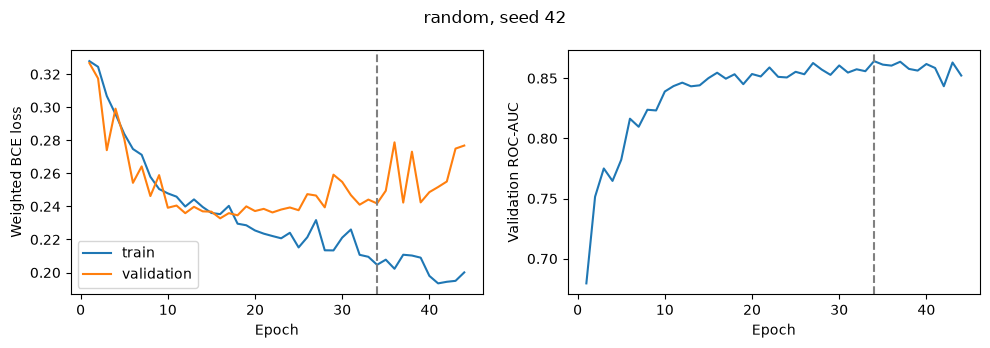

Selected epoch: 34 validation AUC: 0.8643
First and last losses:


,epoch,train_loss,val_loss,val_auc
0,1,0.3279,0.3268,0.6794
43,44,0.2001,0.2768,0.8523


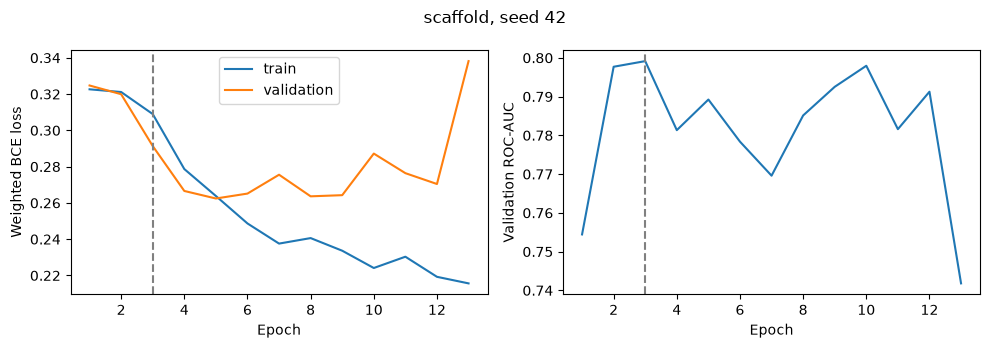

Selected epoch: 3 validation AUC: 0.7992
First and last losses:


,epoch,train_loss,val_loss,val_auc
0,1,0.3226,0.3247,0.7544
12,13,0.2156,0.3382,0.7418


In [ ]:
def plot_history(strategy, seed, result):
    history = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["val_loss"], label="validation")
    axes[0].set_ylabel("Weighted BCE loss")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["val_auc"])
    axes[1].set_ylabel("Validation ROC-AUC")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.axvline(result["best_epoch"], color="gray", linestyle="--")
    fig.suptitle(f"{strategy}, seed {seed}")
    plt.tight_layout()
    fig.savefig(OUT_DIR / f"figures/learning_{strategy}_{seed}.png", dpi=150)
    plt.show()

    best = history.loc[history["epoch"] == result["best_epoch"]].iloc[0]
    print("Selected epoch:", result["best_epoch"], "validation AUC:", round(best.val_auc, 4))
    print("First and last losses:")
    display(history.iloc[[0, -1]].round(4))


for (strategy, seed), result in gnn_runs.items():
    plot_history(strategy, seed, result)

_Interpretation:_

Validation ROC-AUC peaked at epoch 34 (0.8643), and early stopping ended at epoch 44. Training loss fell from 0.328 to 0.200, while validation loss fell from 0.327 to 0.277 overall; the final AUC was below its earlier peak. For scaffold seed 42, AUC peaked at epoch 3 (0.7992), but training continued to epoch 13: training loss fell to 0.216 while validation loss rose to 0.338 from 0.325. This is evidence of overfitting.



### E4. Three seeds for each split strategy [4]

Run three reported GNN seeds per fixed split strategy (six runs). Report mean/std, stating the std convention, and distinguish seed variation from split effects. Freeze a validation-selected threshold for each run before final testing. Final test summaries belong in F.


random 123 epoch 1 val AUC 0.6565


random 123 epoch 10 val AUC 0.844


random 123 epoch 20 val AUC 0.846


random 123 epoch 30 val AUC 0.8611


Selected epoch: 26 threshold: 0.41999999999999993 seconds: 6.5


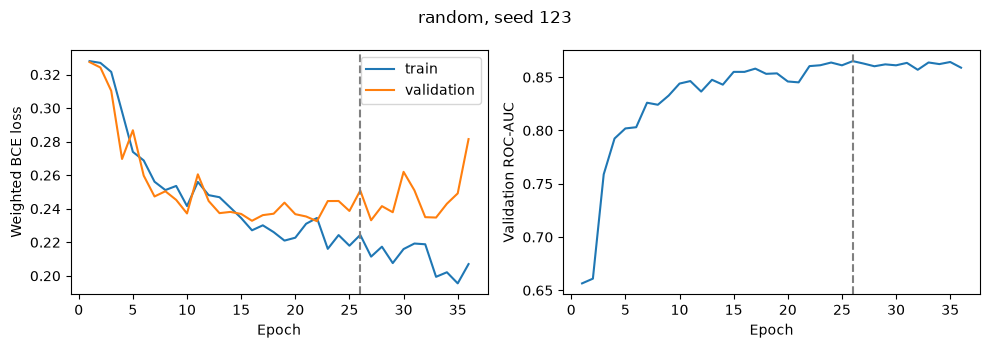

Selected epoch: 26 validation AUC: 0.8651
First and last losses:


,epoch,train_loss,val_loss,val_auc
0,1,0.328,0.3275,0.6565
35,36,0.207,0.2815,0.8589


random 2026 epoch 1 val AUC 0.6945


random 2026 epoch 10 val AUC 0.8477


random 2026 epoch 20 val AUC 0.8489


random 2026 epoch 30 val AUC 0.8538


Selected epoch: 24 threshold: 0.33999999999999997 seconds: 5.8


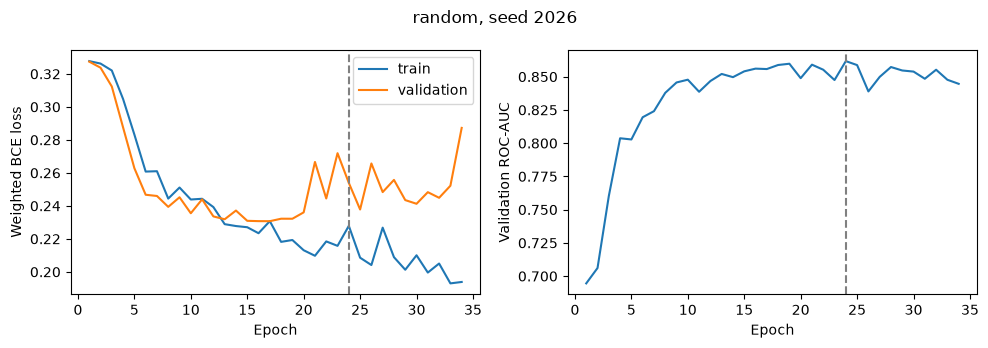

Selected epoch: 24 validation AUC: 0.8617
First and last losses:


,epoch,train_loss,val_loss,val_auc
0,1,0.3277,0.3274,0.6945
33,34,0.1939,0.2873,0.8446


scaffold 123 epoch 1 val AUC 0.7752


scaffold 123 epoch 10 val AUC 0.8


Selected epoch: 5 threshold: 0.24999999999999994 seconds: 2.5


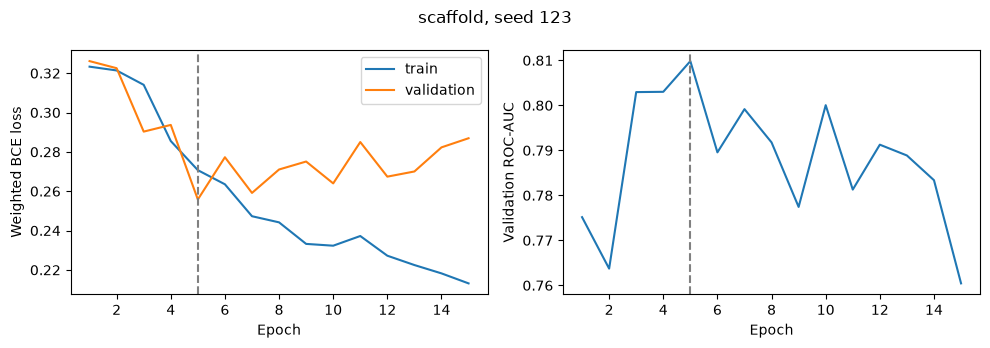

Selected epoch: 5 validation AUC: 0.8098
First and last losses:


,epoch,train_loss,val_loss,val_auc
0,1,0.3233,0.3261,0.7752
14,15,0.2131,0.2869,0.7604


scaffold 2026 epoch 1 val AUC 0.7397


scaffold 2026 epoch 10 val AUC 0.7839


Selected epoch: 8 threshold: 0.09 seconds: 2.9


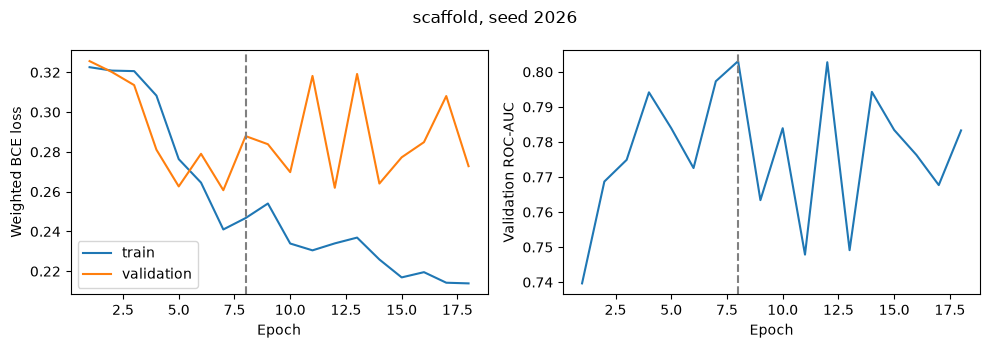

Selected epoch: 8 validation AUC: 0.8031
First and last losses:


,epoch,train_loss,val_loss,val_auc
0,1,0.3226,0.3256,0.7397
17,18,0.2139,0.2728,0.7833


,split,seed,best_epoch,val_auc,threshold,seconds,pos_weight
0,random,42,34,0.8643,0.19,12.8603,0.3095
1,scaffold,42,3,0.7992,0.52,2.7387,0.3033
2,random,123,26,0.8651,0.42,6.4588,0.3095
3,random,2026,24,0.8617,0.34,5.8086,0.3095
4,scaffold,123,5,0.8098,0.25,2.5151,0.3033
5,scaffold,2026,8,0.8031,0.09,2.8605,0.3033


,mean,std
split,,
random,0.8637,0.0018
scaffold,0.8040,0.0054


SD uses ddof=1. Splits stay fixed; only training seeds change.
All models and thresholds are now frozen. Test evaluation begins in F1.


In [ ]:
for strategy in splits:
    for seed in TRAIN_SEEDS[1:]:
        gnn_runs[(strategy, seed)] = train_gnn(strategy, seed)
        plot_history(strategy, seed, gnn_runs[(strategy, seed)])

run_settings = []
for (strategy, seed), result in gnn_runs.items():
    run_settings.append({"split": strategy, "seed": seed, "best_epoch": result["best_epoch"],
        "val_auc": result["val_auc"], "threshold": result["threshold"],
        "seconds": result["seconds"], "pos_weight": result["pos_weight"]})
    
run_settings = pd.DataFrame(run_settings)
display(run_settings.round(4))
display(run_settings.groupby("split")["val_auc"].agg(["mean", "std"]).round(4))

run_settings.to_csv(OUT_DIR / "tables/gnn_settings.csv", index=False)
print("SD uses ddof=1. Splits stay fixed; only training seeds change.")
print("All models and thresholds are now frozen. Test evaluation begins in F1.")

_Interpretation:_

All six runs stopped early. The selected epochs were 34, 26 and 24 for random splitting, and 3, 5 and 8 for scaffold splitting. The three scaffold runs selected checkpoints early, although their training losses kept decreasing.



## F. Evaluate models and splitting strategies (14 marks)


### F1. Final test metrics with validation-selected thresholds [4]

After settings/checkpoints/thresholds are frozen, evaluate both baselines and six GNN runs. Report ROC-AUC, PR-AUC, accuracy, sensitivity, specificity and F1. State PR-AUC convention and undefined-metric handling. Save labels/probabilities/thresholds for reuse.


In [ ]:
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)

METRICS = ["ROC-AUC", "PR-AUC", "accuracy", "sensitivity", "specificity", "F1"]

def metrics(labels, probabilities, threshold):
    predicted = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return {"ROC-AUC": roc_auc_score(labels, probabilities),
            "PR-AUC": average_precision_score(labels, probabilities),
            "accuracy": accuracy_score(labels, predicted),
            "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "F1": f1_score(labels, predicted, zero_division=0)}

final_results = []
final_predictions = {}
for strategy, split in splits.items():
    ids = split["test"]
    baseline = baselines[strategy]
    evaluations = [("Logistic regression", SEED, baseline["threshold"], baseline["model"].predict_proba(X[ids])[:, 1])]

    for seed in TRAIN_SEEDS:
        result = gnn_runs[(strategy, seed)]

        evaluations.append(("GNN", seed, result["threshold"], predict(result["model"], ids)))


    for name, seed, threshold, probabilities in evaluations:
        key = (name, strategy, seed)
        final_predictions[key] = probabilities
        final_results.append({"model": name, "split": strategy, "seed": seed,
                              "threshold": threshold, **metrics(y[ids], probabilities, threshold)})
        pd.DataFrame({"clean_index": ids, "label": y[ids], "probability": probabilities, "threshold": threshold}).to_csv(
            OUT_DIR / f"predictions/{name.replace(' ', '_')}_{strategy}_{seed}.csv", index=False)

results_df = pd.DataFrame(final_results)
results_df.to_csv(OUT_DIR / "tables/test_metrics.csv", index=False)

display(results_df.round(4))


,model,split,seed,threshold,ROC-AUC,PR-AUC,accuracy,sensitivity,specificity,F1
0,Logistic regression,random,42,0.22,0.8917,0.9550,0.8610,0.9733,0.5000,0.9144
1,GNN,random,42,0.19,0.8516,0.9369,0.8542,0.9733,0.4714,0.9106
2,GNN,random,123,0.42,0.8432,0.9344,0.8475,0.9289,0.5857,0.9028
3,GNN,random,2026,0.34,0.8507,0.9345,0.8542,0.9556,0.5286,0.9091
4,Logistic regression,scaffold,42,0.14,0.9040,0.9649,0.8615,0.9775,0.5135,0.9137
5,GNN,scaffold,42,0.52,0.7837,0.9168,0.7973,0.9009,0.4865,0.8696
6,GNN,scaffold,123,0.25,0.8276,0.9373,0.8243,0.9414,0.4730,0.8894
7,GNN,scaffold,2026,0.09,0.8382,0.9395,0.8142,0.9595,0.3784,0.8857


PR-AUC is average precision. Undefined sensitivity/specificity use NaN; undefined F1 uses 0.


_Interpretation_:

PR-AUC is average precision. Undefined sensitivity/specificity use NaN; undefined F1 uses 0.

### F2. ROC, precision–recall curves and confusion matrices [3]

Plot ROC and precision–recall curves and show a confusion matrix for each final test evaluation.


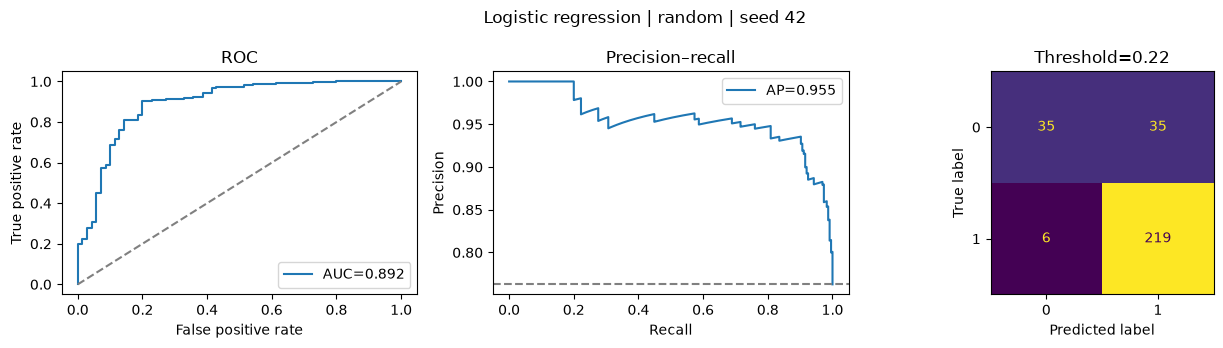

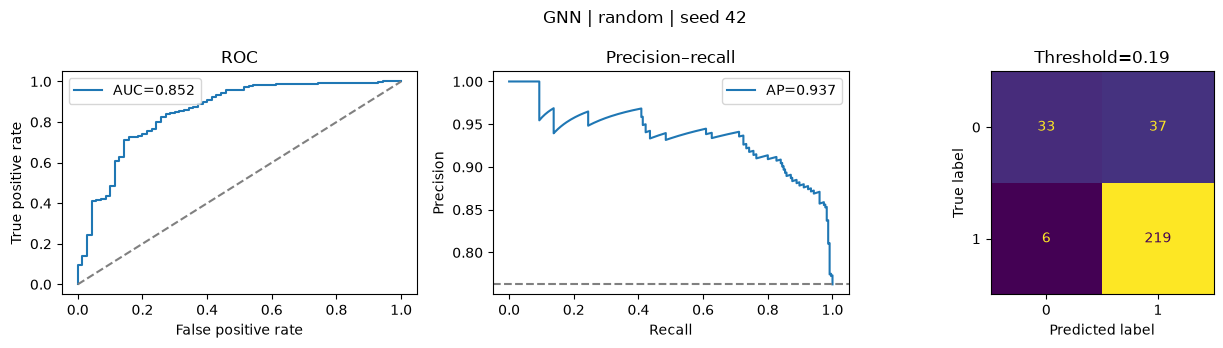

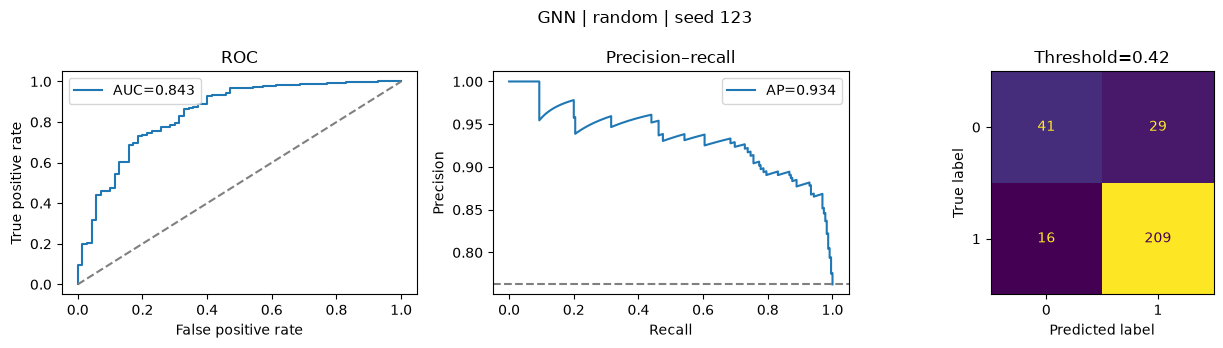

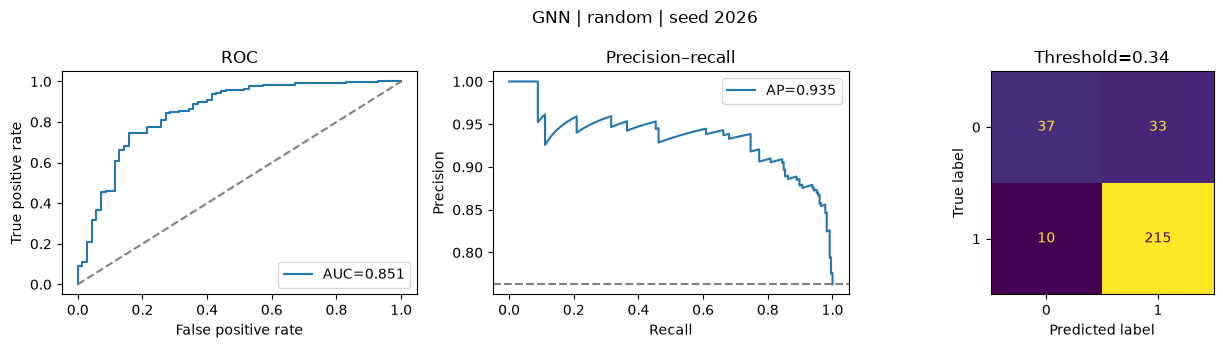

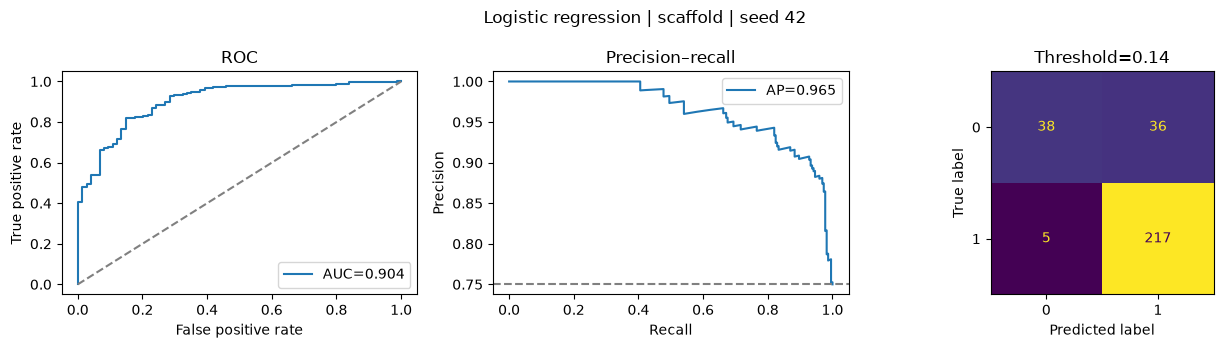

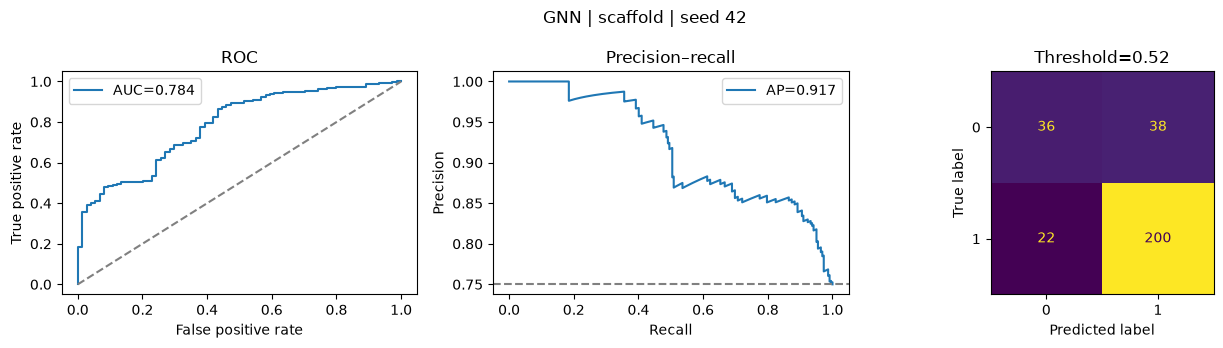

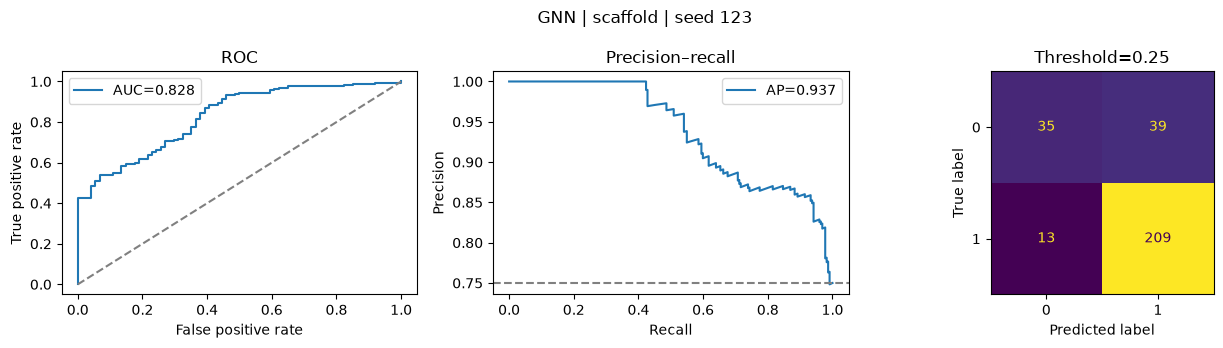

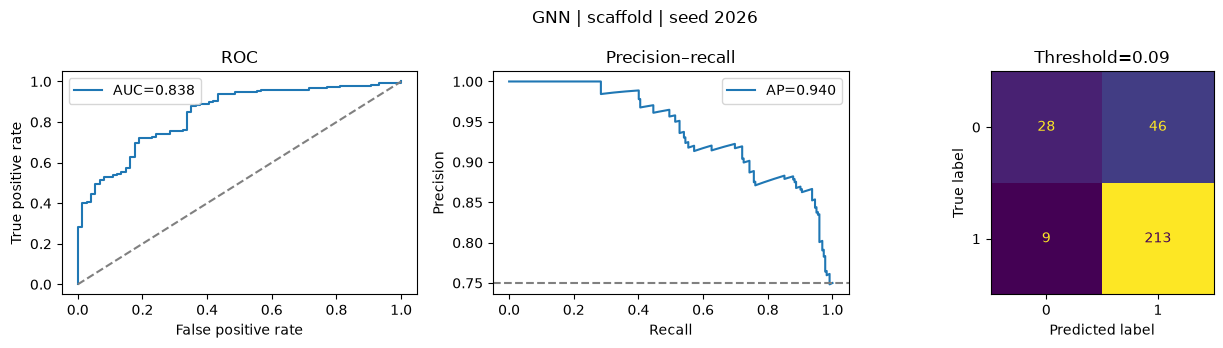

In [ ]:
for row in results_df.to_dict("records"):
    name, strategy, seed = row["model"], row["split"], row["seed"]
    labels = y[splits[strategy]["test"]]
    probabilities = final_predictions[(name, strategy, seed)]
    fpr, tpr, _ = roc_curve(labels, probabilities)
    precision, recall, _ = precision_recall_curve(labels, probabilities)


    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    axes[0].plot(fpr, tpr, label=f"AUC={row['ROC-AUC']:.3f}")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
    axes[0].legend()
    axes[1].plot(recall, precision, label=f"AP={row['PR-AUC']:.3f}")
    axes[1].axhline(labels.mean(), color="gray", linestyle="--")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall")
    axes[1].legend()

    ConfusionMatrixDisplay.from_predictions(labels, probabilities >= row["threshold"], labels=[0, 1], ax=axes[2], colorbar=False)
    
    axes[2].set_title(f"Threshold={row['threshold']:.2f}")
    fig.suptitle(f"{name} | {strategy} | seed {seed}")
    plt.tight_layout()
    fig.savefig(OUT_DIR / f"figures/test_{name.replace(' ', '_')}_{strategy}_{seed}.png", dpi=150)
    plt.show()


_Interpretation:_

Logistic regression achieved higher ROC-AUC and average precision than all three GNN runs under both splitting strategies. GNN performance was lower and more variable under scaffold splitting, suggesting weaker generalization to unseen scaffolds in this experiment. At the validation-selected thresholds, all models showed high sensitivity but relatively low specificity, producing substantial false positives.


### F3. One comparison table and GNN mean/std [3]

Include model, split, threshold and all required metrics in one comparison table. Include seed-level results and GNN mean/std summaries.


In [ ]:
summary_rows = []
for (name, strategy), group in results_df.groupby(["model", "split"], sort=False):
    row = {"model": name, "split": strategy}
    for column in ["threshold"] + METRICS:
        if len(group) == 1:
            row[column] = f"{group[column].iloc[0]:.3f}"
        else:
            row[column] = f"{group[column].mean():.3f} ± {group[column].std(ddof=1):.3f}"
    summary_rows.append(row)
comparison = pd.DataFrame(summary_rows)
display(comparison)
comparison.to_csv(OUT_DIR / "tables/comparison.csv", index=False)




,model,split,threshold,ROC-AUC,PR-AUC,accuracy,sensitivity,specificity,F1
0,Logistic regression,random,0.220,0.892,0.955,0.861,0.973,0.500,0.914
1,GNN,random,0.317 ± 0.117,0.848 ± 0.005,0.935 ± 0.001,0.852 ± 0.004,0.953 ± 0.022,0.529 ± 0.057,0.908 ± 0.004
2,Logistic regression,scaffold,0.140,0.904,0.965,0.861,0.977,0.514,0.914
3,GNN,scaffold,0.287 ± 0.217,0.816 ± 0.029,0.931 ± 0.013,0.812 ± 0.014,0.934 ± 0.030,0.446 ± 0.059,0.882 ± 0.011


GNN rows show mean ± sample SD over three seeds; each run used its own frozen threshold.


### F4. Interpret model and split differences [4]

Compare baseline versus GNN and random versus scaffold evaluation. Explain what the evidence supports; do not assume the GNN wins or that benchmark performance proves biological usefulness.


In [ ]:
mean_results = results_df.groupby(["model", "split"])[METRICS].mean()
display(mean_results.round(4))
for strategy in splits:
    baseline_auc = mean_results.loc[("Logistic regression", strategy), "ROC-AUC"]
    gnn_auc = mean_results.loc[("GNN", strategy), "ROC-AUC"]
    print(strategy, "GNN minus baseline ROC-AUC:", round(gnn_auc - baseline_auc, 4))
for name in ["Logistic regression", "GNN"]:
    gap = mean_results.loc[(name, "random"), "ROC-AUC"] - mean_results.loc[(name, "scaffold"), "ROC-AUC"]
    print(name, "random minus scaffold ROC-AUC:", round(gap, 4))



ROC-AUC  PR-AUC  accuracy  sensitivity  \
model               split                                              
GNN                 random     0.8485  0.9353    0.8520       0.9526   
                    scaffold   0.8165  0.9312    0.8119       0.9339   
Logistic regression random     0.8917  0.9550    0.8610       0.9733   
                    scaffold   0.9040  0.9649    0.8615       0.9775   

                              specificity      F1  
model               split                          
GNN                 random         0.5286  0.9075  
                    scaffold       0.4459  0.8815  
Logistic regression random         0.5000  0.9144  
                    scaffold       0.5135  0.9137

random GNN minus baseline ROC-AUC: -0.0432
scaffold GNN minus baseline ROC-AUC: -0.0875
Logistic regression random minus scaffold ROC-AUC: -0.0123
GNN random minus scaffold ROC-AUC: 0.032
These compare two fixed partitions, not repeated estimates of a split strategy.


_Interpretation:_

The fingerprint baseline had higher test ROC-AUC than the GNN on both partitions. The GNN random–scaffold AUC gap was 0.032, but the baseline scored higher on the scaffold partition. Thus this experiment does not support a universal claim that scaffold evaluation must score lower. Test composition and one fixed partition per strategy limit that comparison. Validation-F1 thresholds favor sensitivity, and baseline sensitivity is about 0.97 but specificity about 0.50. High AP should also be read alongside the roughly 75% positive prevalence. Three seed runs are not a statistical test of model preference.



## G. Error, similarity and limitations analysis (8 marks)


### G1. Scaffold-test false positives and false negatives [2]

Identify the model/run used without selecting it by test performance. Display at least two false positives and two false negatives with labels and probabilities. If insufficient errors exist, report that honestly.


False positives: 38 False negatives: 22


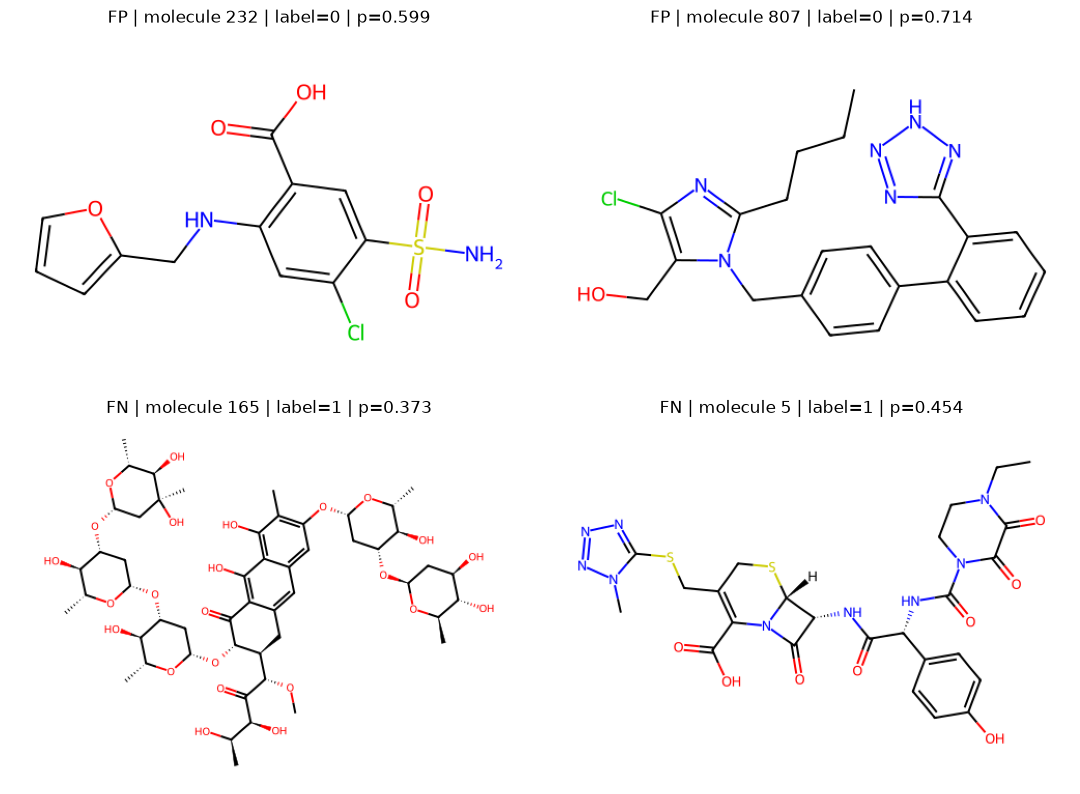

,type,index,smiles,label,probability
0,FP,232,N[S](=O)(=O)c1cc(C(O)=O)c(NCc2occc2)cc1Cl,0,0.599226
1,FP,807,CCCCc1nc(Cl)c(CO)n1Cc2ccc(cc2)c3ccccc3c4n[nH]nn4,0,0.714039
2,FN,165,CO[C@@H]([C@@H]1Cc2cc3cc(O[C@H]4C[C@@H](O[C@H]...,1,0.373100
3,FN,5,CCN1CCN(C(=O)N[C@@H](C(=O)N[C@H]2[C@H]3SCC(=C(...,1,0.453677


In [26]:
# The first seed was fixed for error analysis before testing.
error_model = gnn_runs[("scaffold", ERROR_SEED)]["model"]
error_threshold = gnn_runs[("scaffold", ERROR_SEED)]["threshold"]
test_ids = np.array(scaffold_split["test"])
error_probabilities = final_predictions[("GNN", "scaffold", ERROR_SEED)]
error_labels = y[test_ids]
error_predictions = error_probabilities >= error_threshold
fp = np.where((error_labels == 0) & error_predictions)[0]
fn = np.where((error_labels == 1) & ~error_predictions)[0]
print("False positives:", len(fp), "False negatives:", len(fn))

selected_errors = [("FP", int(i)) for i in fp[:2]] + [("FN", int(i)) for i in fn[:2]]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
error_rows = []
for ax in axes.flat:
    ax.axis("off")
for ax, (kind, position) in zip(axes.flat, selected_errors):
    index = int(test_ids[position])
    smiles = clean_df.iloc[index]["smiles"]
    ax.imshow(Draw.MolToImage(Chem.MolFromSmiles(smiles), size=(500, 350)))
    ax.set_title(f"{kind} | molecule {index} | label={y[index]} | p={error_probabilities[position]:.3f}")
    error_rows.append({"type": kind, "index": index, "smiles": smiles,
                       "label": int(y[index]), "probability": error_probabilities[position]})
plt.tight_layout()
fig.savefig(OUT_DIR / "figures/scaffold_errors.png", dpi=150)
plt.show()
error_table = pd.DataFrame(error_rows)
display(error_table)
error_table.to_csv(OUT_DIR / "tables/errors.csv", index=False)
if len(fp) < 2 or len(fn) < 2:
    print("Fewer than two errors of one type exist; all available examples are shown.")


### G2. Nearest training molecules by Tanimoto similarity [3]

For each selected error, find the most similar training molecule using Morgan-fingerprint Tanimoto similarity. Show the pair, similarity, labels and predictions. Discuss whether similarity explains error or confidence.


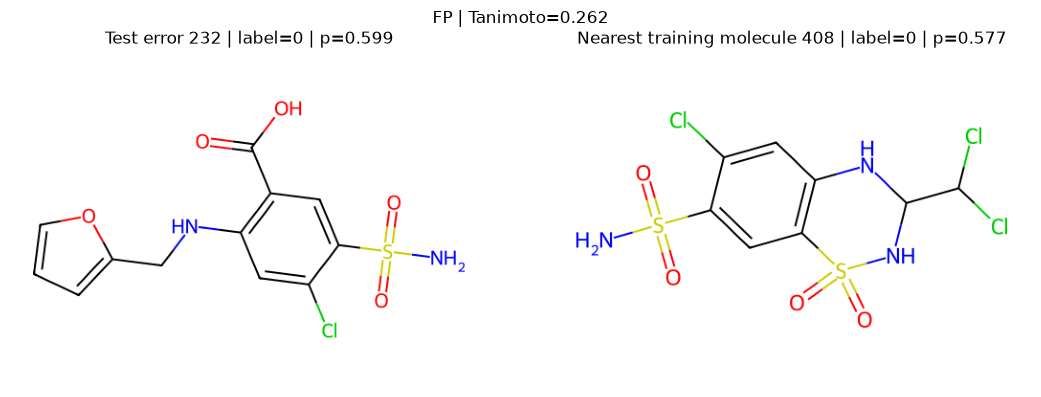

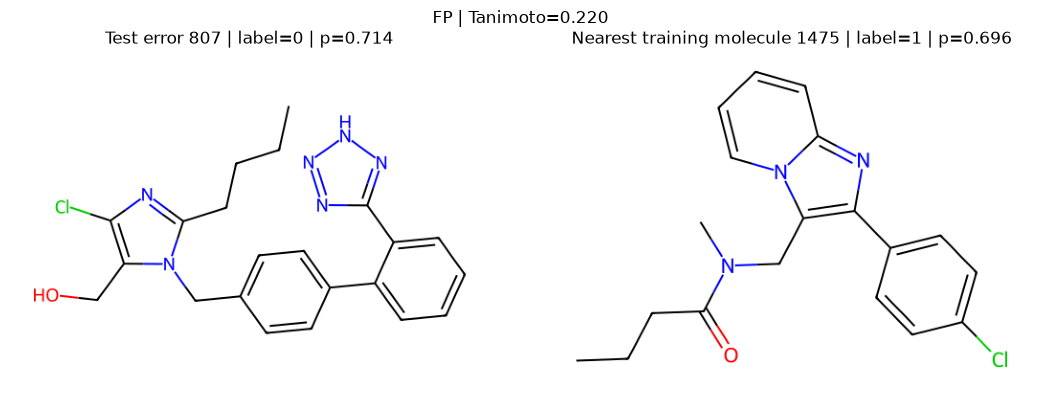

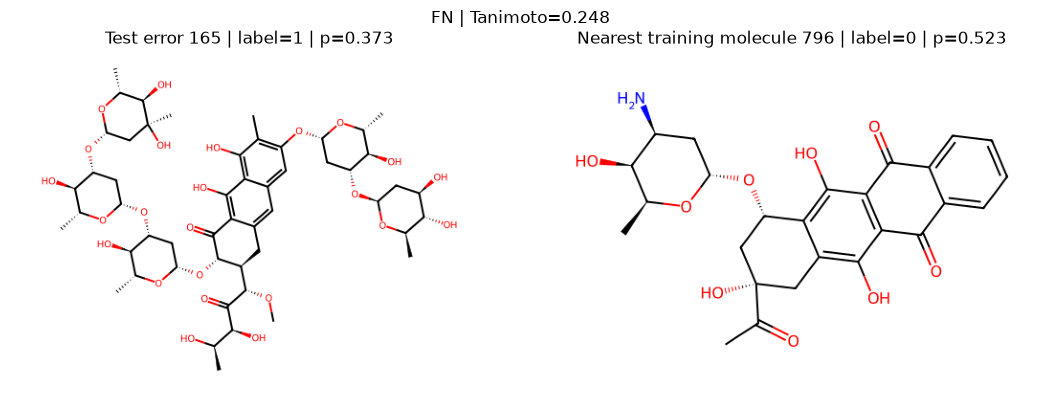

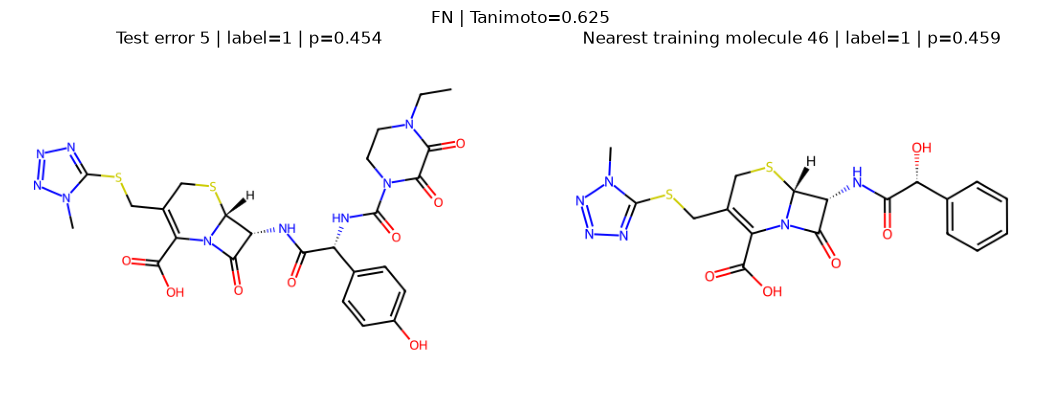

,error_index,error_type,test_label,test_probability,train_index,train_label,train_probability,similarity
0,232,FP,0,0.5992,408,0,0.5768,0.2615
1,807,FP,0,0.7140,1475,1,0.6959,0.2195
2,165,FN,1,0.3731,796,0,0.5234,0.2479
3,5,FN,1,0.4537,46,1,0.4592,0.6250


A shared fingerprint pattern is not proof of the same biological behavior.


In [27]:
from rdkit import DataStructs

train_ids = np.array(scaffold_split["train"])
train_fingerprints = [fingerprints[int(i)] for i in train_ids]
train_probabilities = predict(error_model, train_ids)
pair_rows = []

for error in error_rows:
    index = error["index"]
    similarities = DataStructs.BulkTanimotoSimilarity(fingerprints[index], train_fingerprints)
    nearest_position = int(np.argmax(similarities))
    nearest = int(train_ids[nearest_position])
    similarity = similarities[nearest_position]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    pair = [(index, error["probability"], "Test error"),
            (nearest, train_probabilities[nearest_position], "Nearest training molecule")]
    for ax, (i, probability, title) in zip(axes, pair):
        mol = Chem.MolFromSmiles(clean_df.iloc[i]["smiles"])
        ax.imshow(Draw.MolToImage(mol, size=(500, 350)))
        ax.set_title(f"{title} {i} | label={y[i]} | p={probability:.3f}")
        ax.axis("off")
    fig.suptitle(f"{error['type']} | Tanimoto={similarity:.3f}")
    plt.tight_layout()
    fig.savefig(OUT_DIR / f"figures/similarity_{index}.png", dpi=150)
    plt.show()
    pair_rows.append({"error_index": index, "error_type": error["type"],
        "test_label": y[index], "test_probability": error["probability"],
        "train_index": nearest, "train_label": y[nearest],
        "train_probability": train_probabilities[nearest_position], "similarity": similarity})

similarity_table = pd.DataFrame(pair_rows)
display(similarity_table.round(4))
similarity_table.to_csv(OUT_DIR / "tables/similarity.csv", index=False)
print("A shared fingerprint pattern is not proof of the same biological behavior.")


_Interpretation:_

The nearest-training similarities were 0.262 and 0.220 for the two false positives, and 0.248 and 0.625 for the false negatives. The three low values suggest limited local-pattern overlap with the available training molecules. Molecule 5 had the strongest match (0.625) to training molecule 46; both labels are positive, yet probabilities 0.454 and 0.459 were below the frozen 0.52 threshold. Similarity alone did not prevent a shared classification error. Molecule 232 and its closest training molecule 408 are both negative but were both predicted positive.

### G3. Limitations and scientific scope [3]

State at least three limitations including label uncertainty, dataset size and no external experimental validation. Explain why the model establishes neither causality nor clinical suitability.


In [19]:
print(
    "Labels can be uncertain and combine different experimental conditions.",
    "The dataset is small; three seeds measure training variation, not dataset uncertainty.",
    "There is no external experimental validation or evidence of clinical suitability.",
    "Fingerprints and this GNN omit explicit 3D geometry; fingerprints here also omit chirality.",
    "One scaffold split and its grouped acyclic molecules may not represent every future chemical space.",
)



Labels can be uncertain and combine different experimental conditions. The dataset is small; three seeds measure training variation, not dataset uncertainty. There is no external experimental validation or evidence of clinical suitability. Fingerprints and this GNN omit explicit 3D geometry; fingerprints here also omit chirality. One scaffold split and its grouped acyclic molecules may not represent every future chemical space.


## Submission and oral defence

- [ ] Execute the completed notebook top to bottom and keep outputs visible.
- [ ] Prepare a report of at most six main pages, excluding references and up to two appendix pages; all required material must appear in the main report.
- [ ] Include an accessible GitHub repository link, preferably on page one/footer.
- [ ] Include notebook, supporting Python, README, environment file and AI-use declaration in repository.
- [ ] Exclude downloaded data, caches and large model files. Verify repository access and report filename.
- [ ] Check Moodle for the exact Week 12 deadline and Week 13 defence timing.
- [ ] Practise explaining one graph, one splitting decision, one model result and one error/similarity example.
